In [ ]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

# Data Preparation

## 1. Data augmentation (Cropping panel images)

* In order to enable the CNN model with better perception capabilities to learn attributes (Type, Size, Color, Angle) we intend to make a data augmentation by cropping each element producing several seperate images for each panel.

* We need Bounding Boxes('bbox' from the xml file) to separate the elements from their panels.

* For the special case of `Out_In` structures like, we need to erase the inner shapes from the outer ones after cropping the panel image.

* Cropping results : image with different sizes, so resising results is crucial.

* All images must be tensors.

PS : 
* original panel images are with shape (160,160) (W, H)
* PyTorch prefered default shape format is (C, H, W)
* matplotlib (numpy based) prefered shape is (C, W, H)

## 2. Custom Dataset & DataLoader

In order to prepare the data for training on our `RavenDataset` produces:
* For perception with CNN : 
    * Crops (entityt tensor images [1x80x80]) as `features`
    * Vector-Attributes (Type, Size, Color, Angle) as `labels` 
* For Graph representation with GNN :
    * problem_indices & panel indices : for regrouping crops (making a graph per panel per problem)
    * Vector-Attributes (Type, Size, Color, Angle) as `labels` , which will be used for the `nodes`
    * bboxes for the spacial relationships between crops, which will bes used for the `edges` 

In [ ]:
from torch.utils.data import DataLoader

from hri_gnn.config.const import Configuration
from hri_gnn.datasets import  RavenDataset , gnn_flat_collate


raven_dataset = RavenDataset(dataset="raven-100", split="test",percentage_limit=0.1)
mon_dataloader = DataLoader(
    raven_dataset, 
    batch_size=16,               # Number of RAVEN problems per batch
    shuffle=True,                # Shuffling for the train purposes
    collate_fn=gnn_flat_collate  # for flattening the batch
)



In [ ]:
crops, attrs, bboxes, panel_indices, config_indices, problem_indices, batch_indices =next(iter(mon_dataloader))

In [ ]:
len(raven_dataset)


14

In [ ]:
import torch 

print(f"corp batch shape: {batch_indices.shape}")
print(f"corp shape: {crops.shape}")
print(f"corp config shape: {config_indices.shape}")
print(f"corp problem shape: {problem_indices.shape}")
print(f"corp panel shape: {panel_indices.shape}")
print(f"corp attributes shape: {attrs.shape}")
print(f"corp bboxes shape: {bboxes.shape}")

problems = torch.stack((config_indices,problem_indices), dim=-1)
panels = torch.stack((config_indices, problem_indices, panel_indices), dim=-1)


corp batch shape: torch.Size([649])
corp shape: torch.Size([649, 1, 80, 80])
corp config shape: torch.Size([649])
corp problem shape: torch.Size([649])
corp panel shape: torch.Size([649])
corp attributes shape: torch.Size([649, 4])
corp bboxes shape: torch.Size([649, 4])


In [ ]:
torch.unique(panels, dim=0)[16],torch.unique(problems, dim=0)[0]


(tensor([ 0, 68,  0]), tensor([0, 8]))

corp batch id: 0
corp number: 1 have shape: torch.Size([1, 80, 80])
corp config name: distribute_nine
corp problem id: 28
corp panel id: 0
corp attributes: tensor([1., 1., 0., 4.])
corp bboxes: tensor([0.1600, 0.5000, 0.3300, 0.3300])


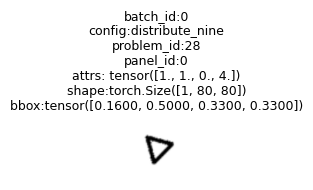

In [ ]:
from hri_gnn.visualization import oracle
from hri_gnn.config.const import Configuration

idx = 1
print(f"corp batch id: {batch_indices[idx]}")
print(f"corp number: {idx} have shape: {crops[idx].shape}")
print(f"corp config name: {Configuration.all()[config_indices[idx]]}")
print(f"corp problem id: {problem_indices[idx]}")
print(f"corp panel id: {panel_indices[idx]}")
print(f"corp attributes: {attrs[idx]}")
print(f"corp bboxes: {bboxes[idx]}")

oracle.plot_crop(
    crops[idx],
    attrs[idx],
    bboxes[idx],
    panel_indices[idx],
    config_indices[idx],
    problem_indices[idx],
    batch_indices[idx])

COMPONENT-0-Grid:
Layout:[Number:6;Uniformity:True]
Elements:
•e0[Pos:5;Type:1;Size:1;Color:0;Angle:4]
•e1[Pos:1;Type:1;Size:1;Color:0;Angle:4]
•e2[Pos:7;Type:1;Size:1;Color:0;Angle:4]
•e3[Pos:3;Type:1;Size:1;Color:0;Angle:4]
•e4[Pos:0;Type:1;Size:1;Color:0;Angle:4]
•e5[Pos:8;Type:1;Size:1;Color:0;Angle:4]



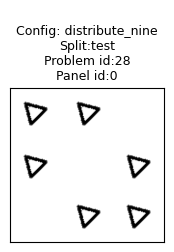

In [ ]:
from hri_gnn.utils.data import readers

problem = readers.read_config_id_problem(config=Configuration.all()[config_indices[idx]], prblm_id=problem_indices[idx].item())
oracle.plot_panel(problem,panel_indices[idx])